In [1]:
import torch, torch.nn as nn, pandas as pd, numpy as np, os
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

OUT = "../data/prepared"
THRESHOLD = 0.5                      # frozen on validation, never changed
ASINS = list(pd.read_csv(f"{OUT}/catalogue.csv")["asin"])
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

class BinDataset(Dataset):
    def __init__(self, group):
        self.group = group
        self.labels = pd.read_csv(f"{OUT}/{group}/labels.csv", index_col=0)[ASINS]
        self.tf = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        img = Image.open(f"{OUT}/{self.group}/{self.labels.index[i]}").convert("RGB")
        return self.tf(img), torch.tensor(self.labels.iloc[i].values, dtype=torch.float32)

test_ds = BinDataset("test")
test_dl = DataLoader(test_ds, batch_size=32, shuffle=False)   # no shuffle: order stays fixed
truth = torch.tensor(test_ds.labels.values, dtype=torch.float32)

def get_raw(model):
    model = model.to(device).eval()
    outs = []
    with torch.no_grad():
        for x, _ in test_dl:
            outs.append(model(x.to(device)).cpu())
    return torch.cat(outs)

# Load the saved models
resnet = models.resnet18(weights=None)
resnet.fc = nn.Linear(resnet.fc.in_features, len(ASINS))
resnet.load_state_dict(torch.load("../models/resnet18_best.pt", map_location=device))

mobile = models.mobilenet_v3_small(weights=None)
mobile.classifier[3] = nn.Linear(mobile.classifier[3].in_features, len(ASINS))
mobile.load_state_dict(torch.load("../models/mobilenet_best.pt", map_location=device))

raw = {"Baseline (always 0)": torch.zeros_like(truth),
       "MobileNetV3-Small": get_raw(mobile),
       "ResNet-18": get_raw(resnet)}

os.makedirs("../outputs", exist_ok=True)
torch.save(raw, "../outputs/test_raw.pt")        # saved so the next steps reuse it

def to_counts(r):
    # present if raw number >= threshold; then round to a count of 1 to 5
    return torch.where(r >= THRESHOLD, r.round().clamp(1, 5), torch.zeros_like(r))

rows = []
for name, r in raw.items():
    pred = to_counts(r)
    tp = ((pred > 0) & (truth > 0)).sum().item()
    fp = ((pred > 0) & (truth == 0)).sum().item()
    fn = ((pred == 0) & (truth > 0)).sum().item()
    p = tp / max(tp + fp, 1); rc = tp / max(tp + fn, 1)
    f1 = 2 * p * rc / max(p + rc, 1e-9)
    real = truth > 0
    rows.append({"model": name,
                 "precision": round(p, 3), "recall": round(rc, 3), "F1": round(f1, 3),
                 "exact (all cells)": round((pred == truth).float().mean().item(), 3),
                 "exact (present only)": round((pred[real] == truth[real]).float().mean().item(), 3),
                 "MAE": round((pred - truth).abs().mean().item(), 3)})

print(pd.DataFrame(rows).set_index("model"))

                     precision  recall     F1  exact (all cells)  \
model                                                              
Baseline (always 0)      0.000   0.000  0.000              0.933   
MobileNetV3-Small        0.816   0.661  0.730              0.956   
ResNet-18                0.903   0.618  0.734              0.961   

                     exact (present only)    MAE  
model                                             
Baseline (always 0)                 0.000  0.088  
MobileNetV3-Small                   0.495  0.050  
ResNet-18                           0.485  0.046  


In [2]:
rng = np.random.default_rng(7)               # fixed seed so the orders are repeatable
bin_ids = list(test_ds.labels.index)
T = truth.numpy()

orders = []
for i, b in enumerate(bin_ids):
    present = np.where(T[i] > 0)[0]
    absent = np.where(T[i] == 0)[0]
    j = rng.choice(present)
    # PASS order: one item really in the bin, with its recorded quantity
    orders.append(dict(row=i, bin_id=b, item=j, qty=int(T[i, j]), should="PASS", kind="true order"))
    # FAIL order: half the time an absent item, half the time one more unit than the bin has
    if rng.random() < 0.5:
        orders.append(dict(row=i, bin_id=b, item=rng.choice(absent), qty=1, should="FAIL", kind="absent item"))
    else:
        orders.append(dict(row=i, bin_id=b, item=j, qty=int(T[i, j]) + 1, should="FAIL", kind="higher quantity"))

orders = pd.DataFrame(orders)
orders.to_csv("../outputs/test_orders.csv", index=False)
print("Orders:", len(orders), "| PASS:", (orders.should == "PASS").sum(), "| FAIL:", (orders.should == "FAIL").sum())

# ---- Let each model judge the orders (photo only, never the labels) ----
def judge(pred):
    found = pred.numpy()[orders["row"], orders["item"]]
    return np.where(found >= orders["qty"], "PASS", "FAIL"), found

for name, r in raw.items():
    result, found = judge(to_counts(r))
    cm = pd.crosstab(orders["should"], pd.Series(result, name="app said")).reindex(
        index=["PASS", "FAIL"], columns=["PASS", "FAIL"], fill_value=0)
    acc = (result == orders["should"]).mean()
    print(f"\n{name}: order accuracy {acc:.3f}")
    print(cm)
    print("  false PASS (wrong order accepted):", cm.loc["FAIL", "PASS"],
          "| false FAIL (good order rejected):", cm.loc["PASS", "FAIL"])

# ---- Wrong predictions of the final model (ResNet-18) ----
names = pd.read_csv(f"{OUT}/catalogue.csv")["product_name"].str[:30].tolist()
res, found = judge(to_counts(raw["ResNet-18"]))
orders["product"] = [names[k] for k in orders["item"]]
orders["found"] = found
orders["raw"] = raw["ResNet-18"].numpy()[orders["row"], orders["item"]].round(2)
orders["app_said"] = res
wrong = orders[orders["app_said"] != orders["should"]]
print("\nWrong predictions:", len(wrong))
print(wrong[["bin_id", "product", "qty", "found", "raw", "kind", "should", "app_said"]].head(12).to_string())

Orders: 600 | PASS: 300 | FAIL: 300

Baseline (always 0): order accuracy 0.500
app said  PASS  FAIL
should              
PASS         0   300
FAIL         0   300
  false PASS (wrong order accepted): 0 | false FAIL (good order rejected): 300

MobileNetV3-Small: order accuracy 0.755
app said  PASS  FAIL
should              
PASS       154   146
FAIL         1   299
  false PASS (wrong order accepted): 1 | false FAIL (good order rejected): 146

ResNet-18: order accuracy 0.742
app said  PASS  FAIL
should              
PASS       149   151
FAIL         4   296
  false PASS (wrong order accepted): 4 | false FAIL (good order rejected): 151

Wrong predictions: 155
        bin_id                         product  qty  found   raw             kind should app_said
4   292299.jpg  Bluedio Turbine T2s Wireless B    1    0.0  0.46       true order   PASS     FAIL
12  261167.jpg  AuYou Wi-Fi Smart Outlet Switc    2    1.0  0.82       true order   PASS     FAIL
18   03545.jpg  Bluedio Turbine T2s Wire

False FAILs where qty = 1: 95 | qty >= 2: 56


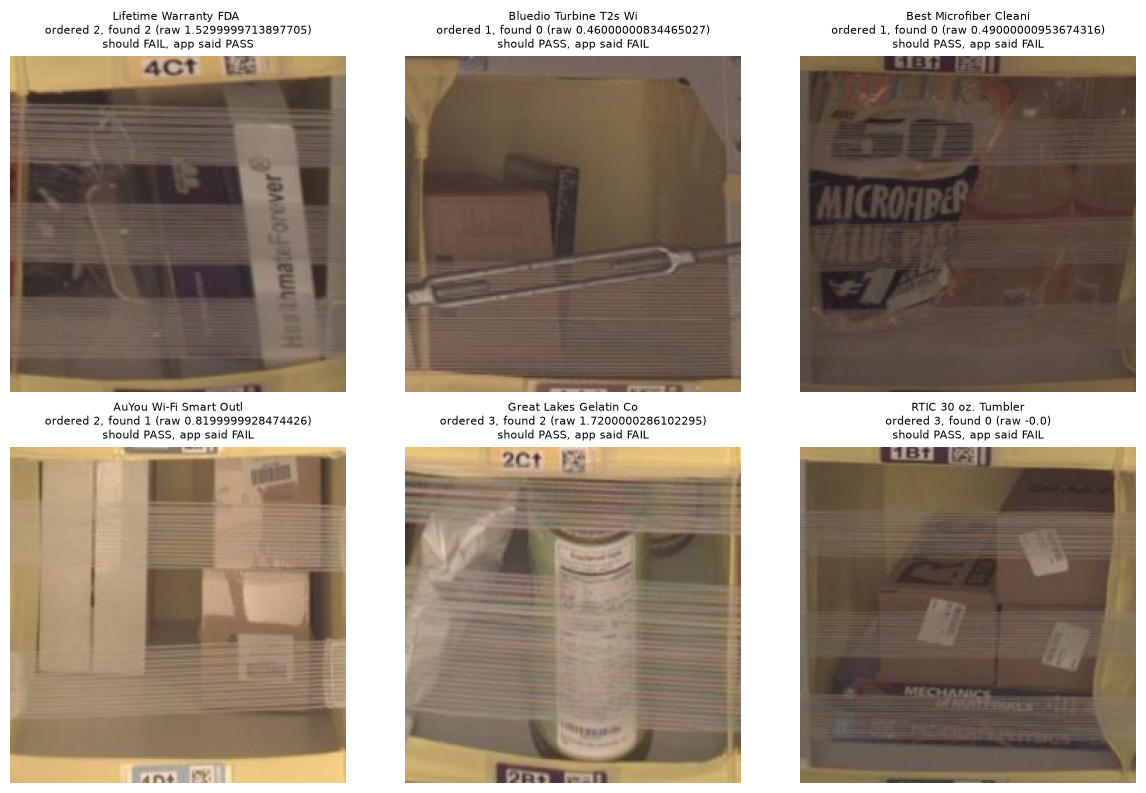

In [3]:
import matplotlib.pyplot as plt

ff = wrong[wrong.should == "PASS"]
print("False FAILs where qty = 1:", (ff.qty == 1).sum(), "| qty >= 2:", (ff.qty >= 2).sum())

pick = ["359715.jpg", "292299.jpg", "339248.jpg", "261167.jpg", "460426.jpg", "107849.jpg"]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, b in zip(axes.flat, pick):
    r = orders[(orders.bin_id == b) & (orders.app_said != orders.should)].iloc[0]
    ax.imshow(Image.open(f"{OUT}/test/{b}"))
    ax.set_title(f"{r['product'][:22]}\nordered {r['qty']}, found {int(r['found'])} (raw {r['raw']})\n"
                 f"should {r['should']}, app said {r['app_said']}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()